# Healthcare Insurance Cost Analysis 
## Project Purpose 
This project analyses recorded healthcare insurance charges using Python. It explores differences in charges by smoking status, age and geographic region. 
## Business Questions 
1. How do recorded charges differ between smokers and non-smokers? 
2. What relationship can be observed between age and recorded charges? 
3. How do average and median charges compare across regions?

## Healthcare Insurance Analytics: 
Industry Applications Data analytics can help healthcare insurance organisations understand costs, identify patterns and support business decisions. Three potential applications are described below. 
### 1. Understanding Medical Cost Patterns 
Healthcare insurers can analyse historical claims and member characteristics to understand how recorded medical costs vary between different groups. This can help analysts identify patterns that require further investigation and support cost planning. 
### 2. Identifying Potentially Fraudulent Claims 
Analytics can be used to examine claims for unusual patterns, repeated billing or values that differ significantly from expected patterns. These findings can help investigation teams prioritise claims for further review. An unusual pattern does not, by itself, prove fraud. 
### 3. Forecasting Healthcare Costs 
Historical claims data can be analysed to estimate future healthcare expenditure. Statistical models and machine learning may help insurers identify patterns associated with higher costs and improve financial planning. Predictions should be evaluated carefully before being used to inform decisions about individuals. 
### Relevance to This Project 
This project focuses on understanding variation in recorded medical insurance charges according to smoking status, age, region and BMI. The analysis uses descriptive statistics and visualisations to explore these relationships. Its findings may help identify patterns for further investigation, but they do not establish causation or provide a validated prediction model.

## Business Problem and Research Questions 
### Business Problem 
Healthcare insurance organisations need to understand how recorded medical insurance costs vary across different groups of insured people. Analysing these differences can help identify patterns in the data and support further investigation and business planning. This project uses the healthcare insurance dataset to explore the relationship between recorded charges and selected personal and geographic characteristics. The analysis is descriptive and focuses on identifying patterns rather than proving cause and effect. 
### Intended Audience 
The intended audience includes healthcare insurance analysts, business decision-makers and other stakeholders who need to understand patterns in recorded medical insurance costs. 
### Research Questions 
This project investigates three main questions: 
1. **Smoking status:** How do recorded charges differ between smokers and non-smokers? 
2. **Age:** What relationship can be observed between age and recorded charges? 
3. **Region:** How do mean and median recorded charges compare across regions? BMI is also explored as an additional variable to investigate its relationship with recorded charges. 
### Analytical Approach 
The project uses data cleaning, descriptive statistics, grouping and aggregation, correlation analysis and visualisations. These methods help summarise the dataset and identify relationships that may be useful for further investigation. The results are associations within the available data and should not be interpreted as proof of causation.

In [2]:
print("Healthcare Insurance Cost Analysis")
print("My assessment project")

Healthcare Insurance Cost Analysis
My assessment project


## Loading and Inspecting the Dataset 
The dataset was loaded from a CSV file into a pandas DataFrame. Initial inspection was carried out to understand the structure of the data before making any changes. The first rows were displayed to preview the records, and the dataset's shape, column names and data types were checked. Missing values and duplicate records were also examined to assess data quality and identify any cleaning that was needed. These initial checks helped establish the condition of the original dataset before the cleaning process began.

In [3]:
import pandas as pd

df = pd.read_csv("../data/insurance.csv")

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (1338, 7)

Column names:
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


### Data Dictionary 
The dataset contains seven columns describing individual characteristics and recorded healthcare insurance charges. | Column | Description | Data type | |---|---|---| | `age` | Age of the individual in years | Integer | | `sex` | Recorded sex category | String | | `bmi` | Body Mass Index value | Float | | `children` | Number of children or dependants recorded | Integer | | `smoker` | Indicates whether the individual is recorded as a smoker | String | | `region` | Geographic region recorded for the individual | String | | `charges` | Recorded healthcare insurance charges | Float | The data types were checked using pandas. The `charges` column is treated as a numerical variable for statistical summaries and visualisations. The dataset source should be consulted to confirm the precise meaning, currency and units of the charges.

## Data Source and Provenance 
The dataset was obtained from Kaggle, under the title *Healthcare Insurance*. The dataset description explains that it contains information about personal attributes, geographic factors and medical insurance charges. It can be used to explore relationships between individual characteristics and recorded insurance costs. The dataset contains seven variables: age, sex, BMI, children, smoker, region and charges. According to the source description, charges represent the medical insurance costs incurred by the insured person. The description does not specify the currency or units, so these have not been assumed in this analysis. The source credits Willian Oliveira as the dataset owner and lists Arun Jangir and Willian Oliveira in the author information. The description states that the data collection method involved conversations with people in hospitals and examining insurance-related data available online. However, it does not provide enough detail to independently verify the collection process or establish the representativeness of the data. The dataset was downloaded as a CSV file and analysed using Python and pandas. The original file was preserved, and a separate cleaned version was created for analysis. The dataset's licence and reuse permissions should be checked on the Kaggle page before redistribution or publication. **Source:** [Kaggle Healthcare Insurance dataset](https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance)

In [5]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Total missing values:
0

Number of duplicate rows:
1


In [6]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [7]:
df_clean = df.drop_duplicates().copy()
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Rows before cleaning: 1338
Rows after cleaning: 1337
Duplicates remaining: 0


## Data Cleaning Decisions 
The initial dataset contained 1,338 rows and seven columns. The checks found no missing values, but one exact duplicate row was identified. This row was removed from the working dataset to prevent the same record from being counted twice in the analysis. After removing the duplicate, the cleaned dataset contained 1,337 rows and seven columns. Validation confirmed that there were no remaining duplicate rows or missing values. The original dataset was kept unchanged, and the cleaned data was saved separately as `insurance_cleaned.csv`. This preserves the raw data and allows the cleaning process to be checked and repeated. The checks also found no unexpected values in the sex, smoker or region categories, and no negative values in the numerical columns examined. Therefore, no further changes were made to those values.

In [8]:
print("Sex values:")
print(df_clean["sex"].value_counts())

print("\nSmoker values:")
print(df_clean["smoker"].value_counts())

print("\nRegion values:")
print(df_clean["region"].value_counts())

print("\nNumerical summary:")
print(df_clean.describe())

Sex values:
sex
male      675
female    662
Name: count, dtype: int64

Smoker values:
smoker
no     1063
yes     274
Name: count, dtype: int64

Region values:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

Numerical summary:
               age          bmi     children       charges
count  1337.000000  1337.000000  1337.000000   1337.000000
mean     39.222139    30.663452     1.095737  13279.121487
std      14.044333     6.100468     1.205571  12110.359656
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.290000     0.000000   4746.344000
50%      39.000000    30.400000     1.000000   9386.161300
75%      51.000000    34.700000     2.000000  16657.717450
max      64.000000    53.130000     5.000000  63770.428010


## Descriptive Statistics 
Descriptive statistics help summarise the main characteristics of the cleaned dataset. Measures such as the mean, median, minimum, maximum and quartiles help show the typical values and variation in the numerical variables. The dataset contains 1,337 records after one duplicate row was removed. The numerical summary provides an overview of age, BMI, number of children and recorded charges. Counts for categorical variables, including sex, smoking status and region, help show how records are distributed across groups. These summaries provide a foundation for the business-question analysis and visualisations that follow.

In [9]:
print("Unexpected sex values:")
print(set(df_clean["sex"].unique()) - {"male", "female"})

print("\nUnexpected smoker values:")
print(set(df_clean["smoker"].unique()) - {"yes", "no"})

print("\nUnexpected region values:")
print(
    set(df_clean["region"].unique())
    - {"southwest", "southeast", "northwest", "northeast"}
)

print("\nNegative values in numerical columns:")
print((df_clean[["age", "bmi", "children", "charges"]] < 0).sum())

Unexpected sex values:
set()

Unexpected smoker values:
set()

Unexpected region values:
set()

Negative values in numerical columns:
age         0
bmi         0
children    0
charges     0
dtype: int64


In [10]:
df_clean.to_csv("../data/insurance_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [11]:
df_check = pd.read_csv("../data/insurance_cleaned.csv")

print("Saved dataset shape:", df_check.shape)
print("Missing values:", df_check.isnull().sum().sum())
print("Duplicate rows:", df_check.duplicated().sum())

df_check.head()

Saved dataset shape: (1337, 7)
Missing values: 0
Duplicate rows: 0


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [12]:
# Compare charges by smoking status
smoker_summary = df_clean.groupby("smoker")["charges"].agg(
    ["count", "mean", "median", "min", "max"]
)

smoker_summary

,count,mean,median,min,max
smoker,,,,,
no,1063,8440.660307,7345.72660,1121.8739,36910.60803
yes,274,32050.231832,34456.34845,12829.4551,63770.42801


Matplotlib is building the font cache; this may take a moment.


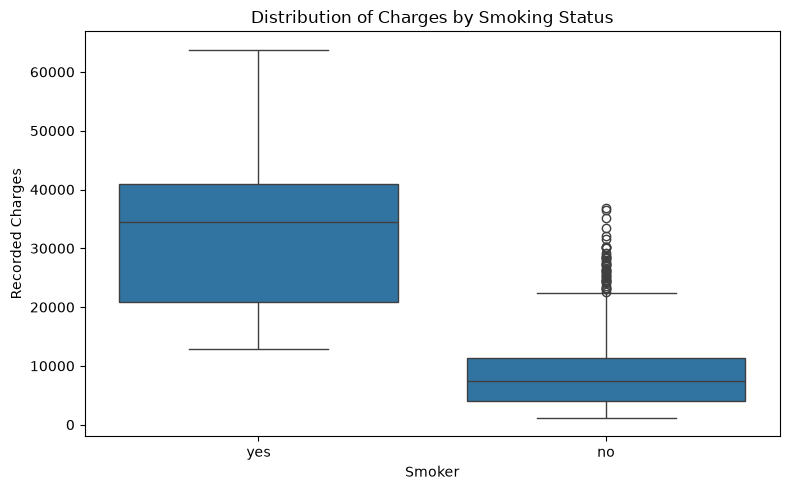

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="smoker", y="charges")

plt.title("Distribution of Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Recorded Charges")
plt.tight_layout()
plt.show()

### Interpretation: charges by smoking status
Charges by Smoking Status The boxplot compares the distribution of recorded insurance charges for smokers and non-smokers. The summary statistics show that smokers have a much higher mean charge (32,050.23) than non-smokers (8,440.66). The median charge is also higher for smokers (34,456.35) compared with non-smokers (7,345.73). These results suggest a strong association between smoking status and higher recorded charges in this dataset. However, this comparison does not establish that smoking alone causes higher charges, as other factors, such as age and BMI, may also influence the observed differences.

In [14]:
# Calculate the correlation between age and charges
age_correlation = df_clean["age"].corr(df_clean["charges"])

print("Correlation between age and charges:", round(age_correlation, 3))

Correlation between age and charges: 0.298


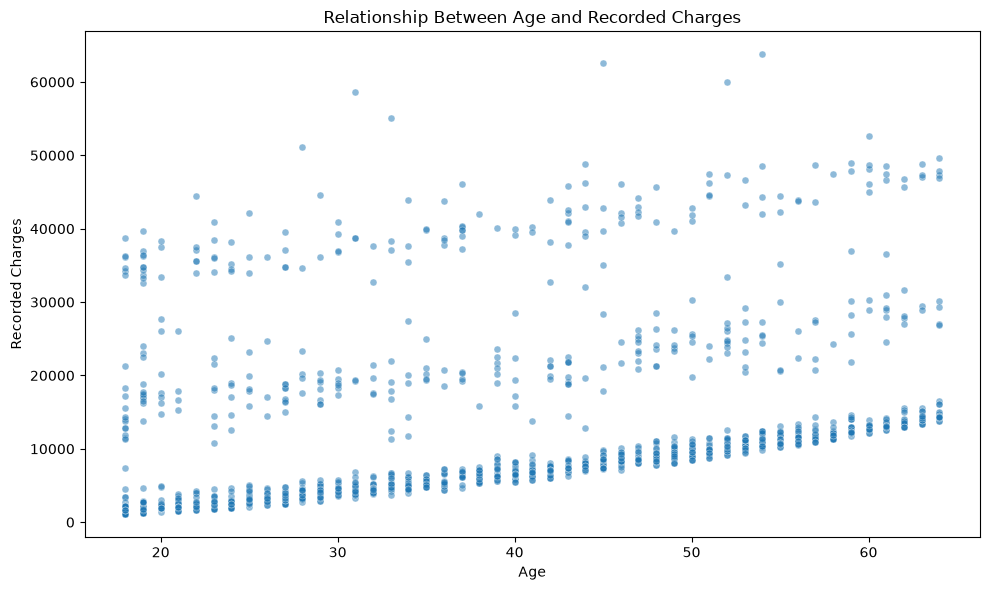

In [16]:
# Visualize the relationship between age and charges
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="age",
    y="charges",
    alpha=0.5,
    s=25
)

plt.title("Relationship Between Age and Recorded Charges")
plt.xlabel("Age")
plt.ylabel("Recorded Charges")
plt.tight_layout()
plt.show()

### Interpretation: Age and Recorded Charges 
The correlation coefficient between age and recorded charges is 0.298, indicating a weak positive linear relationship. The scatter plot helps visualise this relationship and shows how charges vary across different ages. Although recorded charges tend to be higher at older ages, there is considerable variation between individuals of similar ages. This suggests that age alone does not explain the differences in charges. Other factors, including smoking status and BMI, may also be associated with the observed values. These findings describe an association in the dataset and do not establish a causal relationship between age and charges.

In [17]:
# Compare recorded charges across regions
region_summary = df_clean.groupby("region")["charges"].agg(
    ["count", "mean", "median"]
)

region_summary.round(2)

,count,mean,median
region,,,
northeast,324,13406.38,10057.65
northwest,324,12450.84,8976.98
southeast,364,14735.41,9294.13
southwest,325,12346.94,8798.59


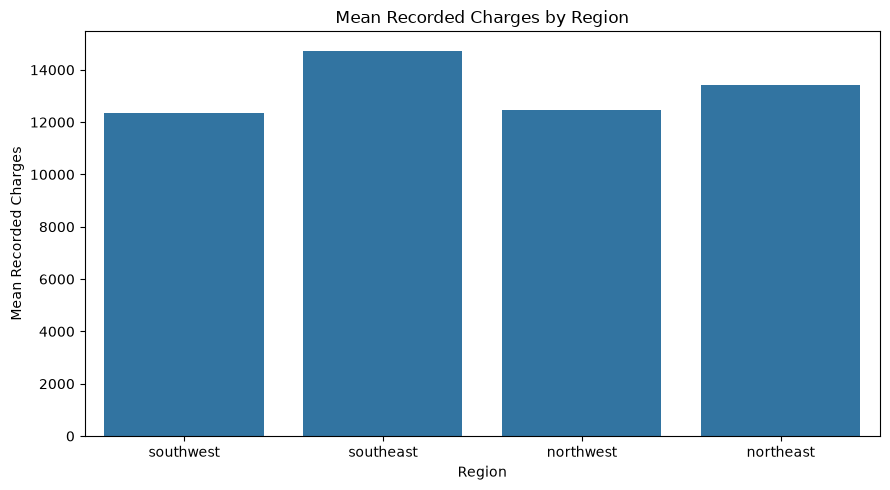

In [18]:
# Compare mean recorded charges by region
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="region",
    y="charges",
    errorbar=None
)

plt.title("Mean Recorded Charges by Region")
plt.xlabel("Region")
plt.ylabel("Mean Recorded Charges")
plt.tight_layout()
plt.show()

### Interpretation: Mean Charges by Region 
The regional comparison shows that the southeast has the highest mean recorded charge at 14,735.41, while the southwest has the lowest at 12,346.94. The northeast has a mean of 13,406.38, and the northwest has a mean of 12,450.84. These results show differences in mean recorded charges across the four regions. However, the chart does not explain why these differences occur. Other factors, such as smoking status, age and BMI, may contribute to the observed pattern.

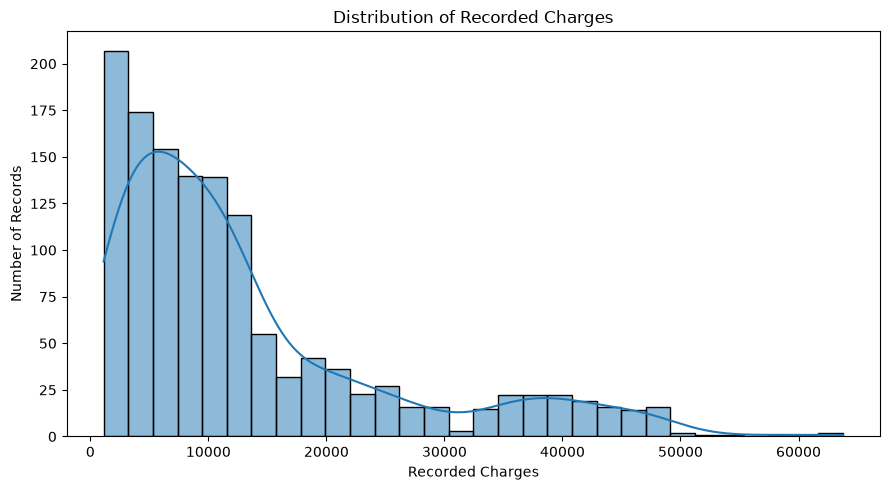

In [19]:
# Show the distribution of recorded charges
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="charges",
    bins=30,
    kde=True
)

plt.title("Distribution of Recorded Charges")
plt.xlabel("Recorded Charges")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

### Interpretation: Distribution of Recorded Charges 
The histogram shows the distribution of recorded charges across the dataset. The charges vary considerably, with some records having much higher values than others. The distribution appears to be right-skewed, meaning that higher charge values extend further to the right. This pattern is consistent with the summary statistics, where the mean charge (13,279.12) is higher than the median charge (9,386.16). A relatively small number of high charges may pull the mean upwards. Understanding the distribution helps identify variation in the data and provides context for comparing charges between different groups. However, the histogram alone does not explain why some records have higher charges.

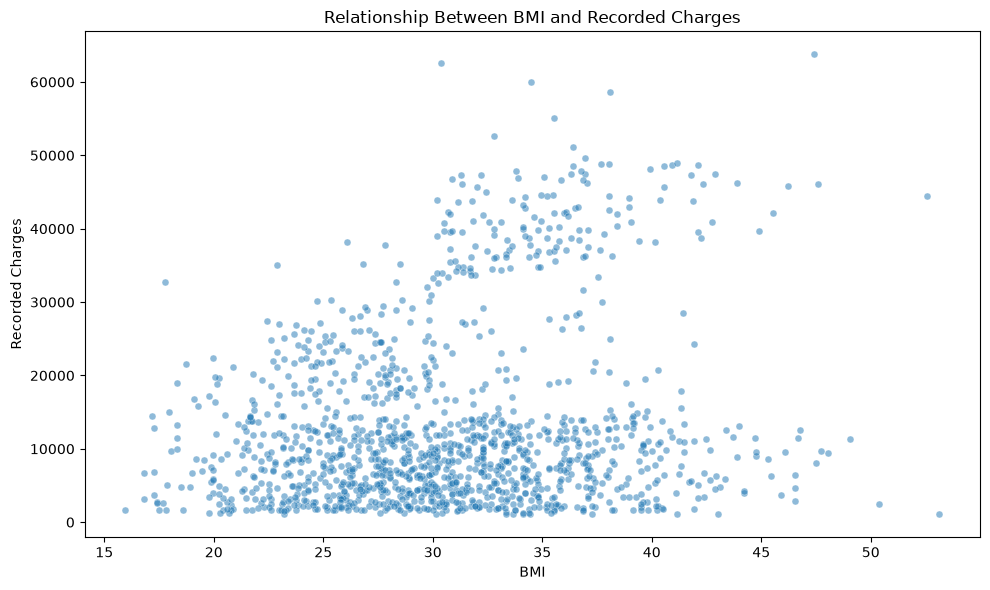

In [20]:
# Explore the relationship between BMI and recorded charges
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="bmi",
    y="charges",
    alpha=0.5,
    s=25
)

plt.title("Relationship Between BMI and Recorded Charges")
plt.xlabel("BMI")
plt.ylabel("Recorded Charges")
plt.tight_layout()
plt.show()

In [21]:
# Calculate the correlation between BMI and charges
bmi_correlation = df_clean["bmi"].corr(df_clean["charges"])

print("Correlation between BMI and recorded charges:", round(bmi_correlation, 3))

Correlation between BMI and recorded charges: 0.198


### Interpretation: BMI and Recorded Charges 
The correlation coefficient between BMI and recorded charges is 0.198, indicating a weak positive linear relationship. This suggests that higher BMI values are associated with a slight tendency towards higher recorded charges in this dataset. The scatter plot shows how charges vary across different BMI values. The weak correlation indicates that BMI alone does not explain most of the variation in recorded charges. Other factors, such as age and smoking status, may also be associated with the observed differences. These findings describe an association within the dataset and do not establish that BMI causes higher charges.

## Overall Findings and Conclusion 
This analysis explored how recorded healthcare insurance charges vary according to smoking status, age, region and BMI. The results showed that smokers had substantially higher mean recorded charges than non-smokers. Age had a weak positive correlation with charges (0.298), while BMI also had a weak positive correlation (0.198). Regional comparisons showed that the southeast had the highest mean recorded charges, while the southwest had the lowest. Overall, the findings suggest that smoking status has the strongest association with recorded charges among the factors examined in this analysis. However, these comparisons do not prove that any factor causes higher charges. Other variables may influence the results, and further analysis would be needed to investigate these relationships in more detail. This analysis demonstrates how data cleaning, descriptive statistics, grouping and visualisations can help identify patterns in a dataset and support evidence-based business decisions.